# Gaming Industry Analysis – Data Analyst Project
**Author:** Hridyansh Sahai | B.Tech 1st Year, CSE-7, ABES Engineering College | **Tools:** Python, pandas, matplotlib, seaborn

## 1. Business problem
A gaming publisher wants to know **which platforms, genres, regions and business models earn the most revenue**, so it can decide where to invest.

**Questions we will answer**
1. How has the industry grown over the years?
2. Which platforms and genres earn the most?
3. Which regions and monetization models perform best?
4. Do marketing budget and ratings affect revenue?
5. Which games are top performers?

> The dataset is **synthetic** (computer-generated) for learning. It is not official industry data.

## 2. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi']=100

## 3. Load and inspect the data

In [2]:
df = pd.read_csv('../data/raw/gaming_industry.csv')
print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (305, 11)


,Game_ID,Release_Year,Platform,Genre,Region,Monetization,Price_USD,Marketing_Budget_MUSD,Avg_Rating,Players_Millions,Revenue_MUSD
0,G2001,2018,Mobile,Action,North America,Free-to-Play,0.00,8.3,3.3,10.90,110.2
1,G2002,2024,Mobile,Action,Europe,Free-to-Play,0.00,6.4,3.9,7.54,115.3
2,G2003,2023,PC,Adventure,Rest of World,Premium,59.99,3.7,3.9,1.28,46.5
3,G2004,2021,Mobile,Shooter,Europe,Free-to-Play,0.00,8.5,4.1,6.59,208.5
4,G2005,2021,PC,Sports,Rest of World,Free-to-Play,0.00,10.1,4.9,3.28,50.6


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Game_ID                305 non-null    str    
 1   Release_Year           305 non-null    int64  
 2   Platform               305 non-null    str    
 3   Genre                  305 non-null    str    
 4   Region                 305 non-null    str    
 5   Monetization           305 non-null    str    
 6   Price_USD              305 non-null    float64
 7   Marketing_Budget_MUSD  299 non-null    float64
 8   Avg_Rating             300 non-null    float64
 9   Players_Millions       301 non-null    float64
 10  Revenue_MUSD           301 non-null    float64
dtypes: float64(5), int64(1), str(5)
memory usage: 26.3 KB


In [4]:
print('Missing values per column:'); print(df.isna().sum()[df.isna().sum()>0])
print('\nDuplicate rows:', df.duplicated().sum())
df.describe().round(1)

Missing values per column:
Marketing_Budget_MUSD    6
Avg_Rating               5
Players_Millions         4
Revenue_MUSD             4
dtype: int64

Duplicate rows: 5


,Release_Year,Price_USD,Marketing_Budget_MUSD,Avg_Rating,Players_Millions,Revenue_MUSD
count,305.0,305.0,299.0,300.0,301.0,301.0
mean,2021.5,11.2,7.7,3.8,5.4,91.7
std,2.2,18.4,5.9,0.6,3.9,80.0
min,2018.0,0.0,0.5,2.3,0.7,1.0
25%,2020.0,0.0,3.8,3.5,2.7,34.4
50%,2021.0,0.0,6.6,3.8,4.4,69.8
75%,2023.0,20.0,9.8,4.2,6.6,119.8
max,2025.0,60.0,35.0,7.5,22.3,457.5


**What we found:** missing values, duplicate rows, inconsistent text in `Platform` (e.g. `mobile`, `CONSOLE`) and an impossible rating above 5. We clean these next.

## 4. Clean the data

In [5]:
clean = df.copy()
# 1. Remove duplicate rows
clean = clean.drop_duplicates()
# 2. Standardise text
clean['Platform'] = clean['Platform'].str.strip().str.title()
clean['Platform'] = clean['Platform'].replace({'Pc':'PC'})
# 3. Fix impossible values (rating must be between 0 and 5)
clean.loc[clean['Avg_Rating']>5,'Avg_Rating'] = np.nan
# 4. Fill missing numbers with the median
num_cols = ['Marketing_Budget_MUSD','Avg_Rating','Players_Millions','Revenue_MUSD']
for col in num_cols:
    clean[col] = clean[col].fillna(clean[col].median())
print('Rows after cleaning:', len(clean), '| Missing values left:', clean.isna().sum().sum())
print(clean['Platform'].unique())

Rows after cleaning: 300 | Missing values left: 0
<StringArray>
['Mobile', 'PC', 'Console']
Length: 3, dtype: str


## 5. Create new columns (feature engineering)

In [6]:
clean['Revenue_Per_Player'] = (clean['Revenue_MUSD']/clean['Players_Millions']).round(2)
clean['ROI'] = (clean['Revenue_MUSD']/clean['Marketing_Budget_MUSD']).round(1)
clean['Rating_Band'] = pd.cut(clean['Avg_Rating'],[0,3,3.5,4,4.5,5],labels=['<3','3-3.5','3.5-4','4-4.5','4.5-5'])
def tier(r):
    if r>=200: return 'Blockbuster'
    if r>=75: return 'Hit'
    if r>=20: return 'Average'
    return 'Low'
clean['Revenue_Tier'] = clean['Revenue_MUSD'].apply(tier)
clean[['Game_ID','Revenue_MUSD','Revenue_Per_Player','ROI','Revenue_Tier']].head()

,Game_ID,Revenue_MUSD,Revenue_Per_Player,ROI,Revenue_Tier
0,G2001,110.2,10.11,13.3,Hit
1,G2002,115.3,15.29,18.0,Hit
2,G2003,46.5,36.33,12.6,Average
3,G2004,208.5,31.64,24.5,Blockbuster
4,G2005,50.6,15.43,5.0,Average


## 6. Exploratory data analysis (EDA)
### Q1. Industry growth over the years

              Revenue  Games
Release_Year                
2018           2700.0     33
2019           2682.0     35
2020           2786.0     37
2021           4034.0     50
2022           2659.0     31
2023           5379.0     43
2024           4132.0     45
2025           3378.0     26


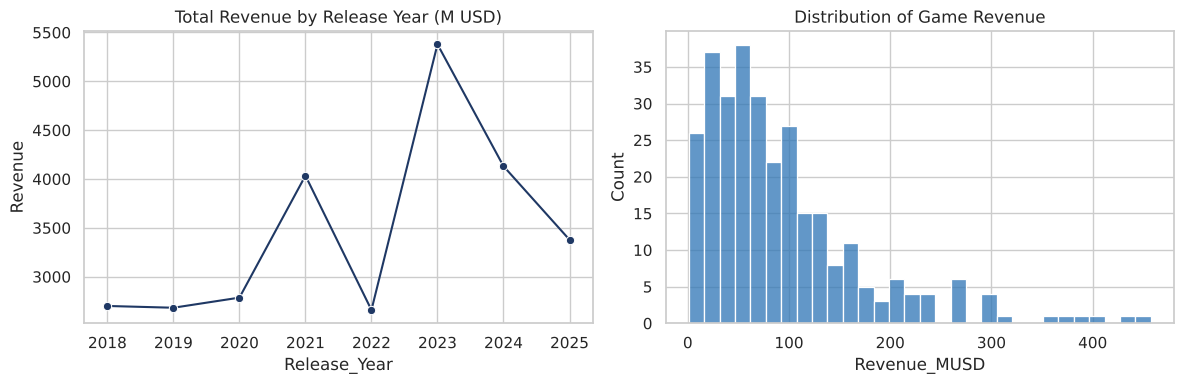

In [7]:
yearly = clean.groupby('Release_Year').agg(Revenue=('Revenue_MUSD','sum'),Games=('Game_ID','count'))
print(yearly.round(0))
fig,ax=plt.subplots(1,2,figsize=(12,4))
sns.lineplot(x=yearly.index,y=yearly['Revenue'],marker='o',color='#1F3864',ax=ax[0]);ax[0].set_title('Total Revenue by Release Year (M USD)')
sns.histplot(clean['Revenue_MUSD'],bins=30,color='#2E75B6',ax=ax[1]);ax[1].set_title('Distribution of Game Revenue')
plt.tight_layout();plt.savefig('../images/01_revenue_trend.png');plt.show()

### Q2. Platforms and genres

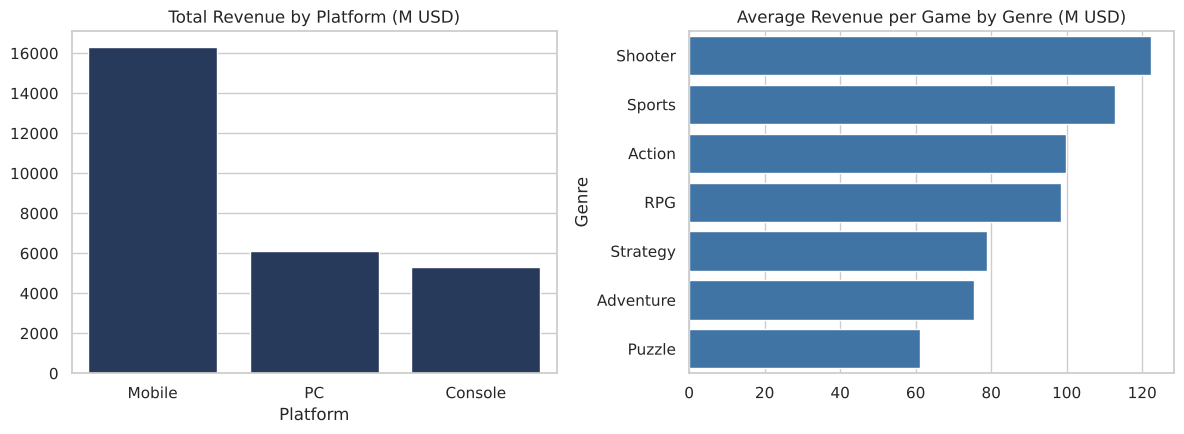

In [8]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
p=clean.groupby('Platform')['Revenue_MUSD'].sum().sort_values(ascending=False)
sns.barplot(x=p.index,y=p.values,color='#1F3864',ax=ax[0]);ax[0].set_title('Total Revenue by Platform (M USD)')
g=clean.groupby('Genre')['Revenue_MUSD'].mean().sort_values(ascending=False)
sns.barplot(x=g.values,y=g.index,color='#2E75B6',ax=ax[1]);ax[1].set_title('Average Revenue per Game by Genre (M USD)')
plt.tight_layout();plt.savefig('../images/02_platform_genre.png');plt.show()

### Q3. Regions and monetization models

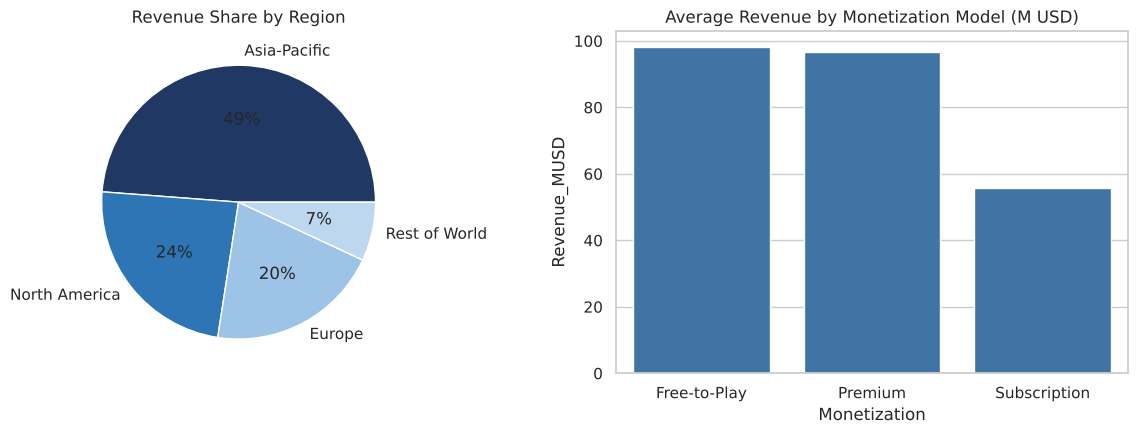

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
r=clean.groupby('Region')['Revenue_MUSD'].sum().sort_values(ascending=False)
ax[0].pie(r.values,labels=r.index,autopct='%1.0f%%',colors=['#1F3864','#2E75B6','#9DC3E6','#BDD7EE']);ax[0].set_title('Revenue Share by Region')
sns.barplot(data=clean,x='Monetization',y='Revenue_MUSD',errorbar=None,color='#2E75B6',ax=ax[1]);ax[1].set_title('Average Revenue by Monetization Model (M USD)')
plt.tight_layout();plt.savefig('../images/03_region_monetization.png');plt.show()

### Q4. Do marketing budget and ratings affect revenue?

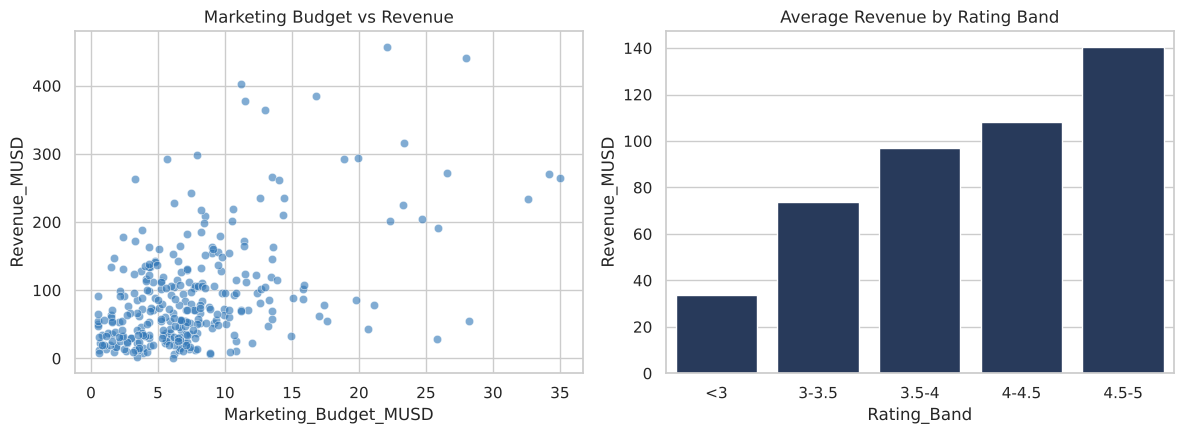

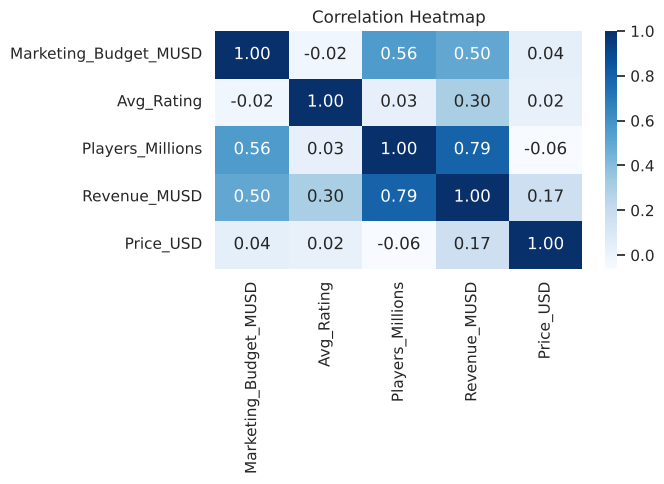

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
sns.scatterplot(data=clean,x='Marketing_Budget_MUSD',y='Revenue_MUSD',alpha=.6,color='#2E75B6',ax=ax[0]);ax[0].set_title('Marketing Budget vs Revenue')
sns.barplot(data=clean,x='Rating_Band',y='Revenue_MUSD',errorbar=None,color='#1F3864',ax=ax[1]);ax[1].set_title('Average Revenue by Rating Band')
plt.tight_layout();plt.savefig('../images/04_marketing_rating.png');plt.show()
plt.figure(figsize=(7,5))
sns.heatmap(clean[num_cols+['Price_USD']].corr().round(2),annot=True,cmap='Blues',fmt='.2f');plt.title('Correlation Heatmap')
plt.tight_layout();plt.savefig('../images/05_correlation.png');plt.show()

### Q5. Top performing games

In [11]:
top=clean.sort_values('Revenue_MUSD',ascending=False)
print(clean['Revenue_Tier'].value_counts())
top[['Game_ID','Platform','Genre','Region','Monetization','Revenue_MUSD']].head(10)

Revenue_Tier
Average        126
Hit            108
Low             36
Blockbuster     30
Name: count, dtype: int64


,Game_ID,Platform,Genre,Region,Monetization,Revenue_MUSD
47,G2048,Mobile,Action,North America,Premium,457.5
43,G2044,Mobile,Sports,Asia-Pacific,Free-to-Play,440.5
155,G2156,Console,Shooter,Asia-Pacific,Free-to-Play,401.9
243,G2244,Mobile,Puzzle,North America,Premium,384.9
178,G2179,Mobile,RPG,Europe,Free-to-Play,378.3
187,G2188,Mobile,Shooter,Asia-Pacific,Free-to-Play,363.8
282,G2283,Mobile,Strategy,Rest of World,Free-to-Play,316.4
27,G2028,Mobile,RPG,Asia-Pacific,Premium,298.7
82,G2083,Mobile,Sports,Asia-Pacific,Free-to-Play,293.5
158,G2159,PC,RPG,Asia-Pacific,Premium,293.2


## 7. Key insights (generated from the data)

In [12]:
r_m=clean['Marketing_Budget_MUSD'].corr(clean['Revenue_MUSD']);r_r=clean['Avg_Rating'].corr(clean['Revenue_MUSD'])
print(f"1. Total revenue in dataset: {clean['Revenue_MUSD'].sum():,.0f} M USD across {len(clean)} games.")
print(f"2. Top platform by revenue: {p.index[0]}; top genre by average revenue: {g.index[0]}.")
print(f"3. Top region: {r.index[0]} ({r.iloc[0]/r.sum():.0%} of revenue).")
print(f"4. Marketing vs revenue correlation = {r_m:.2f}; rating vs revenue = {r_r:.2f}.")
m=clean.groupby('Monetization')['Revenue_MUSD'].mean()
print(f"5. Best monetization model by average revenue: {m.idxmax()} ({m.max():.0f} M USD).")

1. Total revenue in dataset: 27,751 M USD across 300 games.
2. Top platform by revenue: Mobile; top genre by average revenue: Shooter.
3. Top region: Asia-Pacific (49% of revenue).
4. Marketing vs revenue correlation = 0.50; rating vs revenue = 0.30.
5. Best monetization model by average revenue: Free-to-Play (98 M USD).


## 8. Recommendations
- Invest more in the **top platform and genre** shown above.
- Prioritise the **top region** while growing smaller regions.
- Spend marketing budget wisely: it helps revenue, but **quality (rating)** matters too.
- Consider **free-to-play** models where they earn more per game.

> **Remember:** correlation does not prove causation, and this is synthetic data, so findings are illustrative.

## 9. Save the cleaned data

In [13]:
clean.to_csv('../data/processed/gaming_industry_clean.csv',index=False)
print('Saved cleaned file with', len(clean), 'rows')

Saved cleaned file with 300 rows
